# Brain Tumor Classification from MRI Images Using Deep Learning
**AI 342: Deep Learning — Course Project**

**Classes:** Glioma | Meningioma | Pituitary | No Tumor  
**Framework:** PyTorch

## 1. Install & Import Dependencies

In [ ]:
# Install required libraries (run once)
!pip install torch torchvision matplotlib seaborn scikit-learn Pillow tqdm

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')

Using device: cuda


## 2. Mount Google Drive & Load Dataset

> **Setup Instructions:**
> 1. Upload the dataset folder to your Google Drive (e.g. `My Drive/BrainTumorMRI/`).
> 2. The folder must contain two subfolders: `Training/` and `Testing/`,
>    each with class subfolders: `glioma/`, `meningioma/`, `notumor/`, `pituitary/`.
> 3. Run the cell below — it will open a browser pop-up asking you to authorise Drive access.
> 4. Update `DRIVE_DATASET_PATH` to match wherever you placed the dataset in your Drive.

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# ── UPDATE THIS PATH to match your Drive folder structure ─────────────────────
# Example: if you uploaded to 'My Drive/BrainTumorMRI/', use the path below.
DRIVE_DATASET_PATH = '/content/drive/MyDrive/dataset3333'

import os
assert os.path.exists(DRIVE_DATASET_PATH), (
    f'Path not found: {DRIVE_DATASET_PATH}\n'
    '/content/drive/MyDrive/dataset3333'
)
print('Drive mounted. Dataset path found:', DRIVE_DATASET_PATH)
print('Contents:', os.listdir(DRIVE_DATASET_PATH))

Mounted at /content/drive
Drive mounted. Dataset path found: /content/drive/MyDrive/dataset3333
Contents: ['Training', 'Testing']


In [ ]:
# ── Set paths from Google Drive ───────────────────────────────────────────────
DATA_DIR   = DRIVE_DATASET_PATH
TRAIN_DIR  = os.path.join(DATA_DIR, 'Training')
TEST_DIR   = os.path.join(DATA_DIR, 'Testing')

CLASSES = sorted(os.listdir(TRAIN_DIR))
NUM_CLASSES = len(CLASSES)
print('Classes:', CLASSES)
print('Number of classes:', NUM_CLASSES)

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


## 3. Exploratory Data Analysis (EDA)

In [ ]:
def count_samples(base_dir):
    counts = {}
    for cls in sorted(os.listdir(base_dir)):
        cls_path = os.path.join(base_dir, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len(os.listdir(cls_path))
    return counts

train_counts = count_samples(TRAIN_DIR)
test_counts  = count_samples(TEST_DIR)

print('\n--- Dataset Statistics ---')
print(f'{"Class":<15} {"Train":>8} {"Test":>8} {"Total":>8}')
print('-' * 41)
for cls in CLASSES:
    tr = train_counts.get(cls, 0)
    te = test_counts.get(cls, 0)
    print(f'{cls:<15} {tr:>8} {te:>8} {tr+te:>8}')
total_tr = sum(train_counts.values())
total_te = sum(test_counts.values())
print('-' * 41)
print(f'{"TOTAL":<15} {total_tr:>8} {total_te:>8} {total_tr+total_te:>8}')


--- Dataset Statistics ---
Class              Train     Test    Total
-----------------------------------------
glioma              1400      400     1800
meningioma          1400      400     1800
notumor             1403      400     1803
pituitary           1402      400     1802
-----------------------------------------
TOTAL               5605     1600     7205


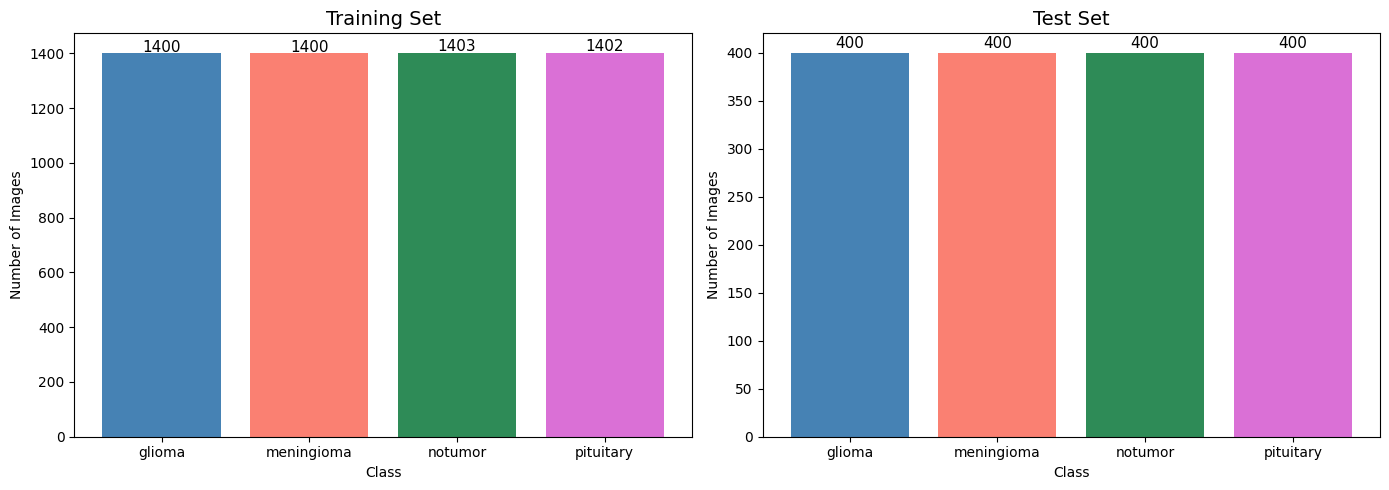

In [ ]:
# Bar chart of class distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (counts, title) in zip(axes, [(train_counts, 'Training Set'), (test_counts, 'Test Set')]):
    ax.bar(counts.keys(), counts.values(), color=['steelblue','salmon','seagreen','orchid'])
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Class')
    ax.set_ylabel('Number of Images')
    for i, (k, v) in enumerate(counts.items()):
        ax.text(i, v + 5, str(v), ha='center', fontsize=11)
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150)
plt.show()

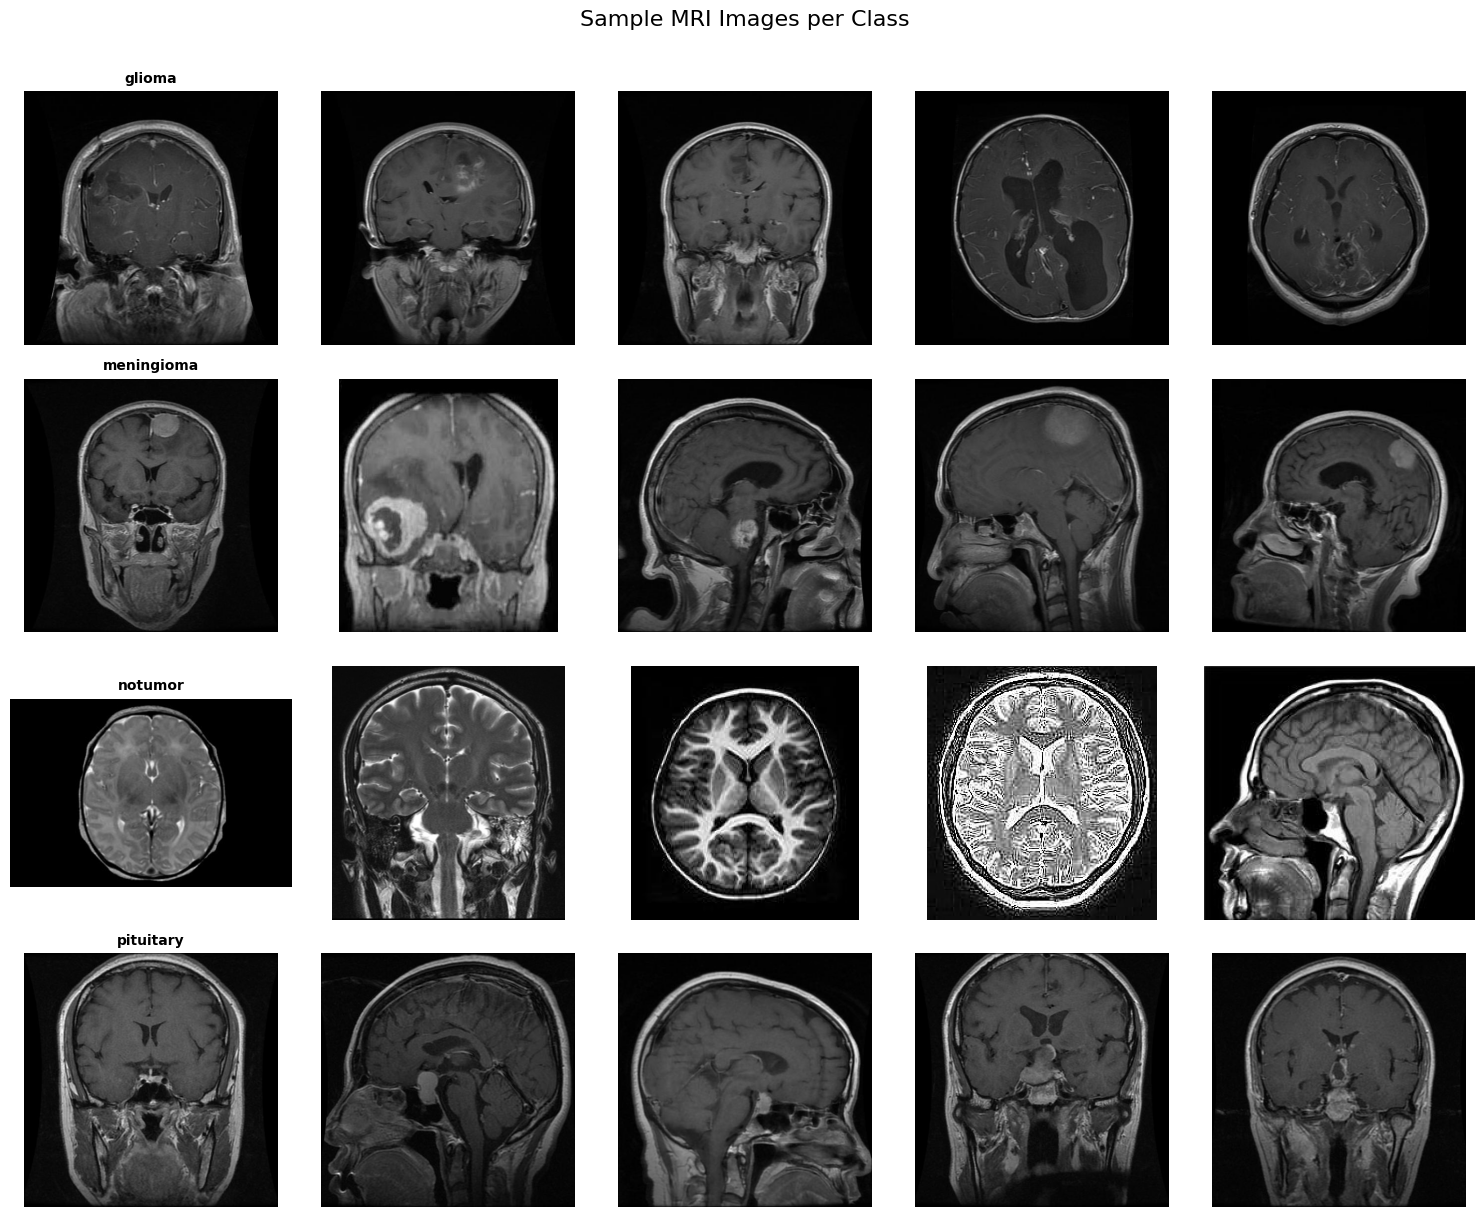

In [ ]:
# Visualise sample images from each class
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(15, 3 * len(CLASSES)))
for row, cls in enumerate(CLASSES):
    cls_path = os.path.join(TRAIN_DIR, cls)
    imgs = random.sample(os.listdir(cls_path), 5)
    for col, img_name in enumerate(imgs):
        img = Image.open(os.path.join(cls_path, img_name)).convert('RGB')
        axes[row, col].imshow(img, cmap='gray')
        axes[row, col].set_title(cls if col == 0 else '', fontsize=10, fontweight='bold')
        axes[row, col].axis('off')
plt.suptitle('Sample MRI Images per Class', fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig('sample_images.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Data Preprocessing & Augmentation

In [ ]:
IMG_SIZE   = 224
BATCH_SIZE = 32
VAL_SPLIT  = 0.2      # 20 % of training data → validation

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])

val_test_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])

# Full training set (augmented)
full_train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transforms)

# Split → train / val
val_size   = int(len(full_train_dataset) * VAL_SPLIT)
train_size = len(full_train_dataset) - val_size
train_dataset, val_dataset = random_split(
    full_train_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

# Apply val/test transforms to the validation subset
val_dataset.dataset = datasets.ImageFolder(TRAIN_DIR, transform=val_test_transforms)

test_dataset  = datasets.ImageFolder(TEST_DIR,  transform=val_test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

CLASS_NAMES = full_train_dataset.classes
print('Class mapping:', full_train_dataset.class_to_idx)
print(f'Train: {train_size} | Val: {val_size} | Test: {len(test_dataset)}')

Class mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Train: 4484 | Val: 1121 | Test: 1600


## 5. CNN Model Definition

In [ ]:
class BrainTumorCNN(nn.Module):
    """Custom CNN for Brain Tumor Classification."""

    def __init__(self, num_classes=4):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2, 2), nn.Dropout2d(0.25),
            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2, 2), nn.Dropout2d(0.25),
            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2, 2), nn.Dropout2d(0.25),
            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.MaxPool2d(2, 2), nn.Dropout2d(0.25),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, 128),         nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


cnn_model = BrainTumorCNN(num_classes=NUM_CLASSES).to(DEVICE)
print(cnn_model)
total_params = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)
print(f'\nTrainable parameters: {total_params:,}')

BrainTumorCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.25, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): Dropout2d(p=0.2

## 6. Transfer Learning — ResNet-18 (Fine-tuned)

In [ ]:
resnet_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all layers except the final FC
for param in resnet_model.parameters():
    param.requires_grad = False

# Replace the head
resnet_model.fc = nn.Sequential(
    nn.Linear(resnet_model.fc.in_features, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, NUM_CLASSES)
)
resnet_model = resnet_model.to(DEVICE)

trainable = sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)
print(f'ResNet-18 trainable parameters: {trainable:,}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 178MB/s]


ResNet-18 trainable parameters: 132,356


## 7. Training Utilities

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for inputs, labels in tqdm(loader, desc='Training', leave=False):

        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * inputs.size(0)

        _, preds = outputs.max(1)

        correct += preds.eq(labels).sum().item()

        total += labels.size(0)

    return running_loss / total, correct / total


def evaluate(model, loader, criterion):

    model.eval()

    running_loss, correct, total = 0.0, 0, 0

    all_preds, all_labels = [], []

    with torch.no_grad():

        for inputs, labels in tqdm(loader, desc='Evaluating', leave=False):

            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)

            _, preds = outputs.max(1)

            correct += preds.eq(labels).sum().item()

            total += labels.size(0)

            all_preds.extend(preds.cpu().numpy())

            all_labels.extend(labels.cpu().numpy())

    return running_loss / total, correct / total, all_preds, all_labels


def train_model(model, train_loader, val_loader,
                num_epochs=25,
                lr=1e-3,
                model_name='model',
                weight_decay=1e-4):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr,
        weight_decay=weight_decay
    )

    # FIXED HERE
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        patience=4,
        factor=0.5
    )

    history = {
        'train_loss': [],
        'val_loss': [],
        'train_acc': [],
        'val_acc': []
    }

    best_val_acc = 0.0

    for epoch in range(1, num_epochs + 1):

        tr_loss, tr_acc = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        vl_loss, vl_acc, _, _ = evaluate(
            model,
            val_loader,
            criterion
        )

        scheduler.step(vl_loss)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(vl_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(vl_acc)

        print(
            f'[{model_name}] Epoch {epoch:02d}/{num_epochs} '
            f'| Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} '
            f'| Val Loss: {vl_loss:.4f} Acc: {vl_acc:.4f}'
        )

        if vl_acc > best_val_acc:

            best_val_acc = vl_acc

            torch.save(
                model.state_dict(),
                f'best_{model_name}.pth'
            )

            print(f'✓ Saved best model (val_acc={best_val_acc:.4f})')

    return history

## 8. Train Custom CNN

In [ ]:
CNN_EPOCHS = 30

cnn_history = train_model(
    cnn_model,
    train_loader,
    val_loader,
    num_epochs=CNN_EPOCHS,
    lr=1e-3,
    model_name='cnn'
)

KeyboardInterrupt: 

## 9. Train ResNet-18 (Transfer Learning)

In [ ]:
RESNET_EPOCHS = 20
resnet_history = train_model(
    resnet_model, train_loader, val_loader,
    num_epochs=RESNET_EPOCHS, lr=5e-4,
    model_name='resnet'
)

## 10. Training Curves

In [ ]:
def plot_history(history, title='Training History', save_as=None):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history['train_loss'], label='Train Loss')
    axes[0].plot(history['val_loss'],   label='Val Loss')
    axes[0].set_title(f'{title} — Loss')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
    axes[0].legend()

    axes[1].plot([a*100 for a in history['train_acc']], label='Train Acc')
    axes[1].plot([a*100 for a in history['val_acc']],   label='Val Acc')
    axes[1].set_title(f'{title} — Accuracy')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy (%)')
    axes[1].legend()

    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=150)
    plt.show()

plot_history(cnn_history,    title='Custom CNN',   save_as='cnn_training_curves.png')
plot_history(resnet_history, title='ResNet-18 TL', save_as='resnet_training_curves.png')

## 11. Evaluate on Test Set — CNN & ResNet

In [ ]:
criterion = nn.CrossEntropyLoss()

# Load best weights
cnn_model.load_state_dict(torch.load('best_cnn.pth', map_location=DEVICE))
resnet_model.load_state_dict(torch.load('best_resnet.pth', map_location=DEVICE))

_, cnn_acc, cnn_preds, cnn_true       = evaluate(cnn_model,    test_loader, criterion)
_, resnet_acc, resnet_preds, resnet_true = evaluate(resnet_model, test_loader, criterion)

print(f'\nCustom CNN  Test Accuracy: {cnn_acc*100:.2f}%')
print(f'ResNet-18   Test Accuracy: {resnet_acc*100:.2f}%')

In [ ]:
def plot_confusion_matrix(y_true, y_pred, class_names, title='Confusion Matrix', save_as=None):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title, fontsize=14)
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=150)
    plt.show()

plot_confusion_matrix(cnn_true,    cnn_preds,    CLASS_NAMES, 'Custom CNN — Confusion Matrix',   'cm_cnn.png')
plot_confusion_matrix(resnet_true, resnet_preds, CLASS_NAMES, 'ResNet-18  — Confusion Matrix',   'cm_resnet.png')

In [ ]:
def print_report(y_true, y_pred, model_name):
    print(f'\n{"="*50}')
    print(f'Classification Report — {model_name}')
    print('='*50)
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

print_report(cnn_true,    cnn_preds,    'Custom CNN')
print_report(resnet_true, resnet_preds, 'ResNet-18')

## 12. Baseline Models — Logistic Regression & SVM

Features are extracted as flattened, resized grayscale images (fast baseline).

In [ ]:
from sklearn.preprocessing import StandardScaler

BASELINE_SIZE = 64   # resize for speed

def extract_features(base_dir, img_size=BASELINE_SIZE):
    X, y = [], []
    for label, cls in enumerate(sorted(os.listdir(base_dir))):
        cls_path = os.path.join(base_dir, cls)
        if not os.path.isdir(cls_path):
            continue
        for fname in os.listdir(cls_path):
            fpath = os.path.join(cls_path, fname)
            try:
                img = Image.open(fpath).convert('L').resize((img_size, img_size))
                X.append(np.array(img).flatten() / 255.0)
                y.append(label)
            except Exception:
                pass
    return np.array(X), np.array(y)

print('Extracting training features...')
X_train_bl, y_train_bl = extract_features(TRAIN_DIR)
print('Extracting test features...')
X_test_bl,  y_test_bl  = extract_features(TEST_DIR)

scaler = StandardScaler()
X_train_bl = scaler.fit_transform(X_train_bl)
X_test_bl  = scaler.transform(X_test_bl)

print(f'Train shape: {X_train_bl.shape} | Test shape: {X_test_bl.shape}')

In [ ]:
# Logistic Regression
print('Training Logistic Regression...')
lr_clf = LogisticRegression(max_iter=1000, random_state=SEED, n_jobs=-1)
lr_clf.fit(X_train_bl, y_train_bl)
lr_preds = lr_clf.predict(X_test_bl)
lr_acc   = accuracy_score(y_test_bl, lr_preds)
print(f'Logistic Regression Test Accuracy: {lr_acc*100:.2f}%')
print(classification_report(y_test_bl, lr_preds, target_names=CLASS_NAMES))

In [ ]:
# SVM  (RBF kernel — may take a few minutes on large datasets)
print('Training SVM...')
svm_clf = SVC(kernel='rbf', C=10, gamma='scale', random_state=SEED)
svm_clf.fit(X_train_bl, y_train_bl)
svm_preds = svm_clf.predict(X_test_bl)
svm_acc   = accuracy_score(y_test_bl, svm_preds)
print(f'SVM Test Accuracy: {svm_acc*100:.2f}%')
print(classification_report(y_test_bl, svm_preds, target_names=CLASS_NAMES))

## 13. Model Comparison Summary

In [ ]:
models_summary = {
    'Logistic Regression (Baseline)': (y_test_bl,   lr_preds),
    'SVM (Baseline)':                 (y_test_bl,   svm_preds),
    'Custom CNN':                     (cnn_true,    cnn_preds),
    'ResNet-18 (Transfer Learning)':  (resnet_true, resnet_preds),
}

print(f'\n{"Model":<35} {"Accuracy":>10} {"Precision":>10} {"Recall":>10} {"F1":>10}')
print('='*77)
rows = []
for name, (true, pred) in models_summary.items():
    acc  = accuracy_score(true, pred)
    prec = precision_score(true, pred, average='macro', zero_division=0)
    rec  = recall_score(true, pred, average='macro', zero_division=0)
    f1   = f1_score(true, pred, average='macro', zero_division=0)
    print(f'{name:<35} {acc*100:>9.2f}% {prec*100:>9.2f}% {rec*100:>9.2f}% {f1*100:>9.2f}%')
    rows.append((name, acc, prec, rec, f1))

# Bar chart
names   = [r[0] for r in rows]
accs    = [r[1]*100 for r in rows]
colors  = ['#d62728', '#ff7f0e', '#1f77b4', '#2ca02c']

plt.figure(figsize=(12, 5))
bars = plt.bar(names, accs, color=colors, edgecolor='black')
for bar, acc in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{acc:.1f}%', ha='center', fontsize=11, fontweight='bold')
plt.ylim(0, 115)
plt.ylabel('Test Accuracy (%)', fontsize=12)
plt.title('Model Comparison — Test Accuracy', fontsize=14)
plt.xticks(rotation=15, ha='right')
plt.axhline(85, color='red', linestyle='--', linewidth=1.5, label='Target (85%)')
plt.legend()
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()

## 14. Grad-CAM Explainability (for CNN)

In [ ]:
# Simple Grad-CAM implementation (no external library needed)
import torch.nn.functional as F
import cv2

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.gradients = None
        self.activations = None
        target_layer.register_forward_hook(self._save_activations)
        target_layer.register_backward_hook(self._save_gradients)

    def _save_activations(self, module, inp, out):
        self.activations = out.detach()

    def _save_gradients(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()
        output = self.model(input_tensor)
        if class_idx is None:
            class_idx = output.argmax(dim=1).item()
        self.model.zero_grad()
        output[0, class_idx].backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx


# Attach Grad-CAM to last conv layer of custom CNN
# (the last Conv2d inside the features block — index varies; find it dynamically)
last_conv = None
for m in cnn_model.features.modules():
    if isinstance(m, nn.Conv2d):
        last_conv = m

grad_cam = GradCAM(cnn_model, last_conv)
print('Grad-CAM ready on layer:', last_conv)

In [ ]:
def show_gradcam(model, grad_cam_obj, dataset, class_names, n=4, save_as=None):
    fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))
    indices = random.sample(range(len(dataset)), n)
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])

    for row, idx in enumerate(indices):
        img_tensor, true_label = dataset[idx]
        inp = img_tensor.unsqueeze(0).to(DEVICE)
        cam, pred_label = grad_cam_obj.generate(inp)

        # Denormalise for display
        raw = img_tensor.permute(1, 2, 0).numpy()
        raw = np.clip(raw * std + mean, 0, 1)

        cam_resized = np.array(Image.fromarray((cam * 255).astype(np.uint8)).resize(
            (IMG_SIZE, IMG_SIZE), Image.BILINEAR)) / 255.0
        heatmap = plt.cm.jet(cam_resized)[..., :3]
        overlay = np.clip(0.5 * raw + 0.5 * heatmap, 0, 1)

        axes[row, 0].imshow(raw)
        axes[row, 0].set_title(f'Original\nTrue: {class_names[true_label]}', fontsize=9)
        axes[row, 0].axis('off')

        axes[row, 1].imshow(cam_resized, cmap='jet')
        axes[row, 1].set_title('Grad-CAM Heatmap', fontsize=9)
        axes[row, 1].axis('off')

        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title(f'Overlay\nPred: {class_names[pred_label]}', fontsize=9)
        axes[row, 2].axis('off')

    plt.suptitle('Grad-CAM Explainability — Custom CNN', fontsize=14, y=1.01)
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=150, bbox_inches='tight')
    plt.show()

show_gradcam(cnn_model, grad_cam, test_dataset, CLASS_NAMES, n=4, save_as='gradcam.png')

## 15. Misclassification Analysis

In [ ]:
cnn_true_arr  = np.array(cnn_true)
cnn_preds_arr = np.array(cnn_preds)
wrong_indices = np.where(cnn_true_arr != cnn_preds_arr)[0]

print(f'Misclassified samples: {len(wrong_indices)} / {len(cnn_true_arr)}')

# Show some misclassified images
n_show = min(8, len(wrong_indices))
sample_wrong = random.sample(list(wrong_indices), n_show)
mean = np.array([0.485, 0.456, 0.406])
std  = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for ax, idx in zip(axes, sample_wrong):
    img_tensor, _ = test_dataset[idx]
    raw = img_tensor.permute(1, 2, 0).numpy()
    raw = np.clip(raw * std + mean, 0, 1)
    ax.imshow(raw)
    ax.set_title(f'True: {CLASS_NAMES[cnn_true_arr[idx]]}\nPred: {CLASS_NAMES[cnn_preds_arr[idx]]}',
                 fontsize=9, color='red')
    ax.axis('off')

plt.suptitle('Misclassified Samples — Custom CNN', fontsize=14)
plt.tight_layout()
plt.savefig('misclassified.png', dpi=150)
plt.show()

## 16. Save Models & Final Summary

In [ ]:
torch.save(cnn_model.state_dict(),    'final_cnn_model.pth')
torch.save(resnet_model.state_dict(), 'final_resnet_model.pth')
print('Models saved.')

print('\n' + '='*60)
print('FINAL PROJECT RESULTS SUMMARY')
print('='*60)
print(f'  Logistic Regression (Baseline): {lr_acc*100:.2f}%')
print(f'  SVM (Baseline):                 {svm_acc*100:.2f}%')
print(f'  Custom CNN:                     {cnn_acc*100:.2f}%')
print(f'  ResNet-18 (Transfer Learning):  {resnet_acc*100:.2f}%')
print('='*60)
target_met = cnn_acc >= 0.85 or resnet_acc >= 0.85
print(f'  Target (≥85%) met: {"✓ YES" if target_met else "✗ NO — consider more epochs"}')
print('='*60)